# Same-input projector comparison with Tidy3D

This is a frequency-domain projector comparison: both methods receive identical complex E/H samples, frequency, origin, and target grid. No source resampling or independent output normalization is used. MAPS geometry is in SI units; the Tidy3D monitor and projection coordinates are expressed in µm. The 2e-5 relative complex E/H threshold is the repository regression gate.

|E|² is shown as an intensity proxy, not power flux in W/m². Flux requires both E and H through the Poynting vector. If Tidy3D or xarray is unavailable, the shared input and MAPS projection still run and the optional comparison reports its dependency status. Errors from an installed incompatible Tidy3D version remain visible.


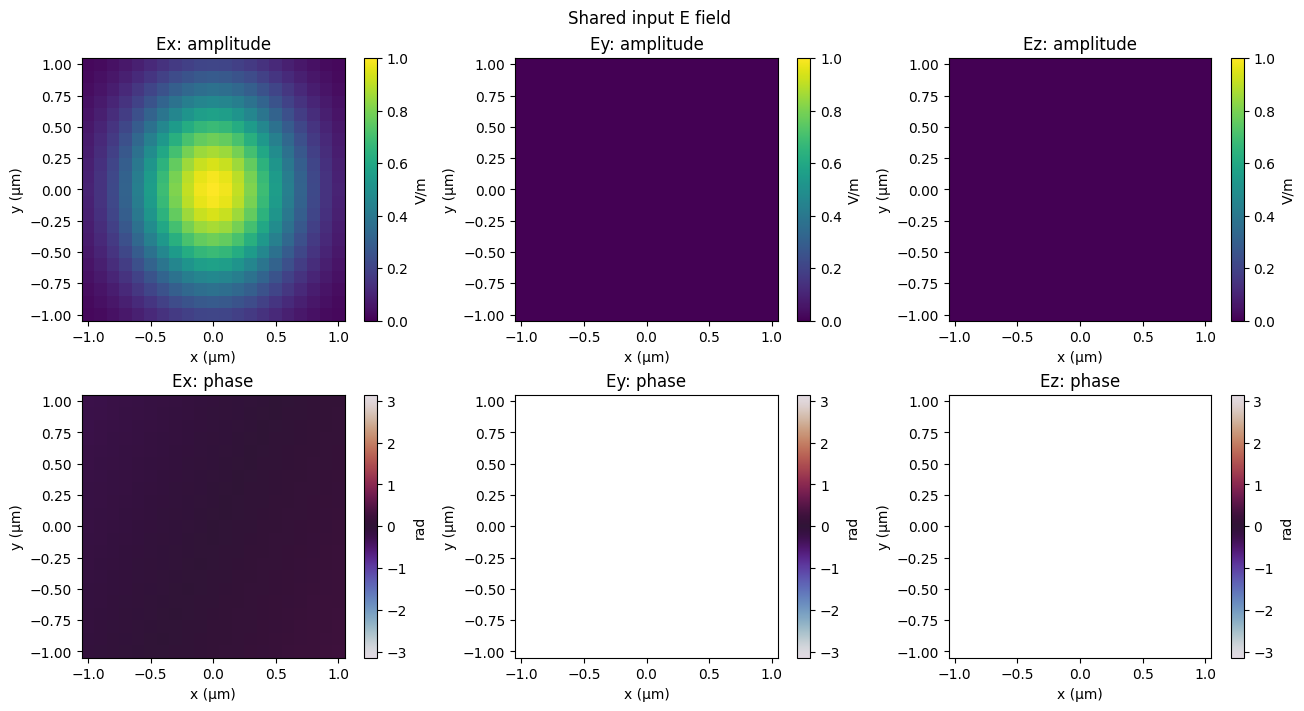

Device=cuda; source grid=21×21; λ=1.5501 µm


In [ ]:
from pathlib import Path
import sys

ROOT = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "core" / "nearfield").is_dir()
    ),
    None,
)
if ROOT is None:
    raise RuntimeError("Could not locate repository root containing core/nearfield")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "examples/nearfield"))
import numpy as np, torch, matplotlib.pyplot as plt
from IPython.display import display
from core.nearfield import make_planar_surface, project_nearfield
from notebook_utils import (
    field_components,
    field_comparison,
    error_summary,
    show_errors,
    surface_copy,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
freq = 193.4e12
wavelength = 299792458.0 / freq
u = torch.linspace(-1e-6, 1e-6, 21, dtype=torch.float64)
yy, xx = torch.meshgrid(u, u, indexing="ij")
a = torch.exp(-((xx / 0.65e-6) ** 2 + (yy / 0.8e-6) ** 2))
p = 0.25 * xx / wavelength - 0.12 * yy / wavelength
ex = (a * torch.exp(1j * p)).to(torch.complex128)
e = torch.zeros((1, 21, 21, 3), dtype=torch.complex128)
h = torch.zeros_like(e)
e[0, ..., 0] = ex
h[0, ..., 1] = ex / 376.730313668
surface_ref = make_planar_surface(
    torch.zeros(3, dtype=torch.float64),
    torch.tensor([1.0, 0, 0], dtype=torch.float64),
    torch.tensor([0, 1.0, 0], dtype=torch.float64),
    u,
    u,
    e,
    h,
    torch.tensor([freq], dtype=torch.float64),
)
_ = field_components(
    e[0].numpy(),
    u.numpy() * 1e6,
    u.numpy() * 1e6,
    title="Shared input E field",
    quantity="E",
    units="V/m",
)
print(f"Device={DEVICE}; source grid=21×21; λ={wavelength*1e6:.4f} µm")

00:04:34 MST WARNING: Monitor data requires 'grid_expanded' to be defined to    
             compute values like flux, Poynting and dot product with other data.

             WARNING: Monitor data requires 'grid_expanded' to be defined to    
             compute values like flux, Poynting and dot product with other data.

00:04:35 MST WARNING: Monitor data requires 'grid_expanded' to be defined to    
             compute values like flux, Poynting and dot product with other data.

             WARNING: Monitor data requires 'grid_expanded' to be defined to    
             compute values like flux, Poynting and dot product with other data.

Output()

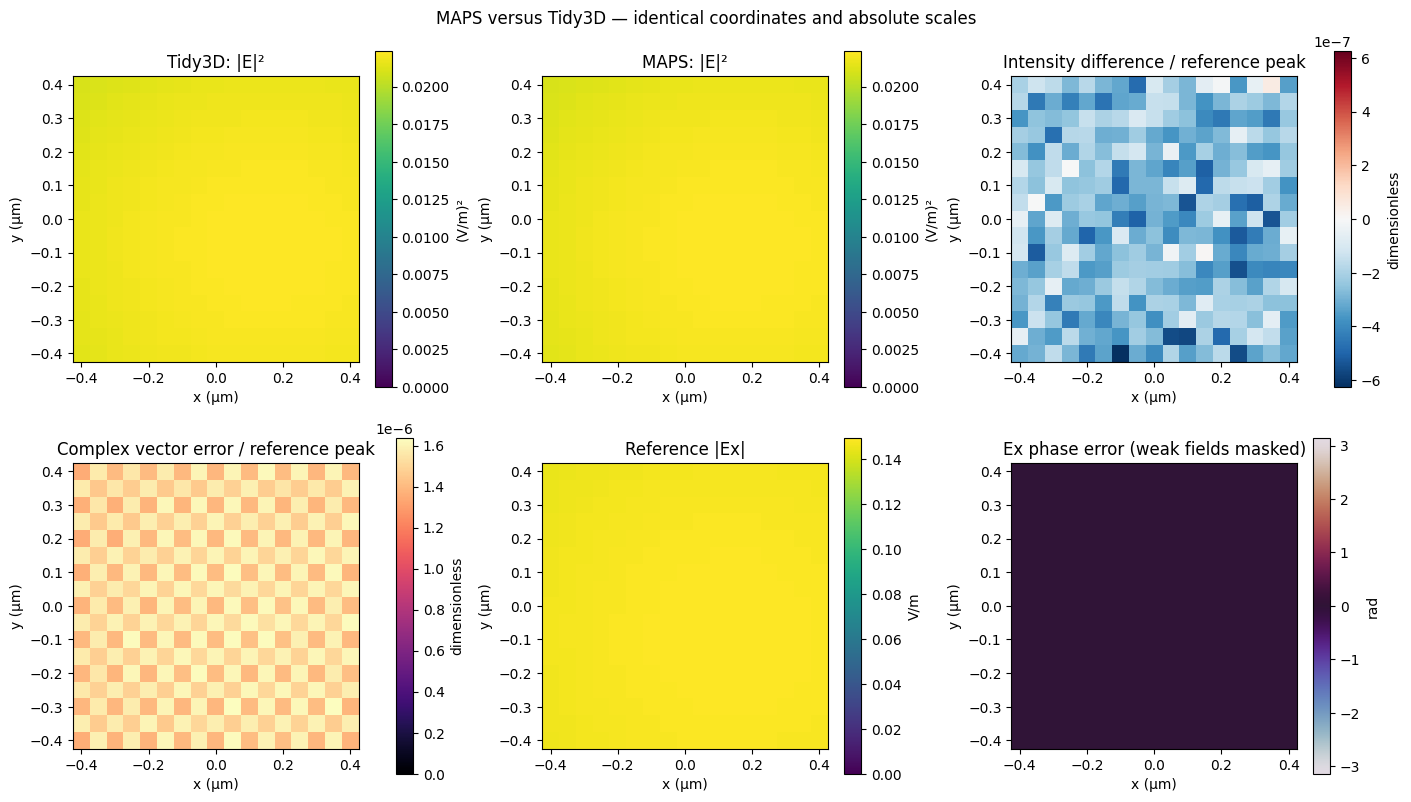

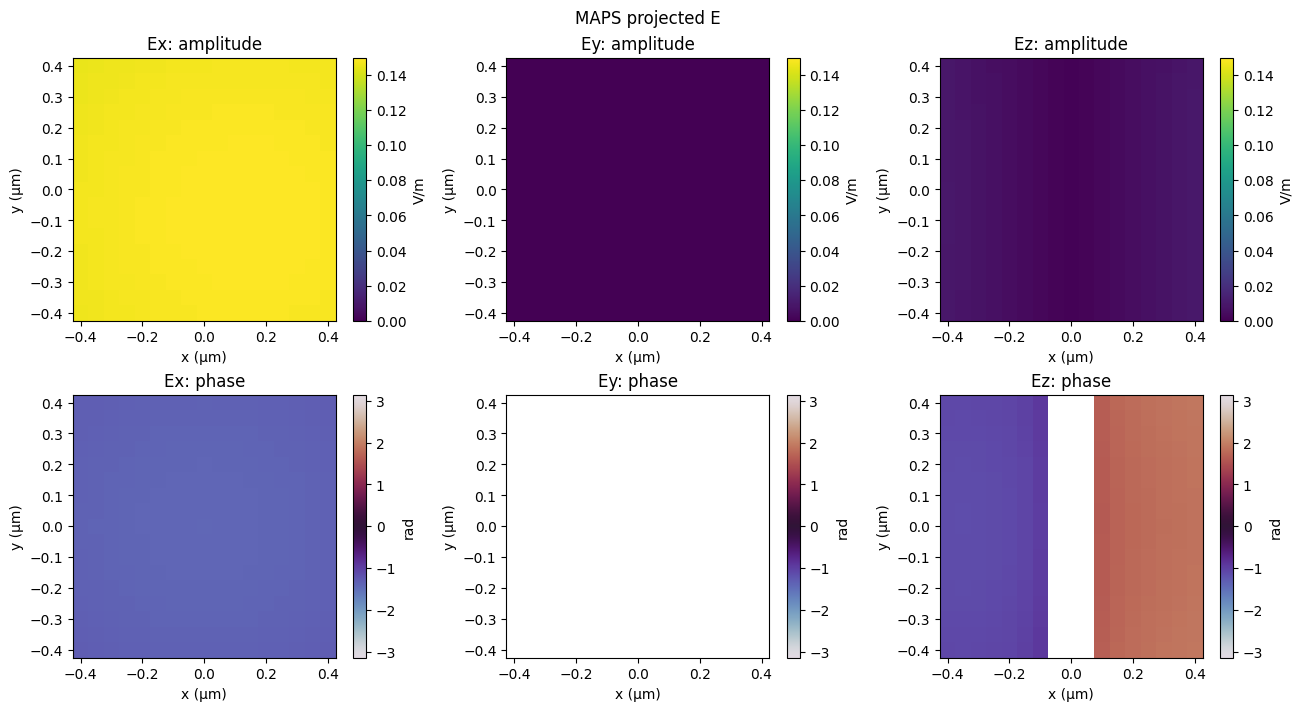

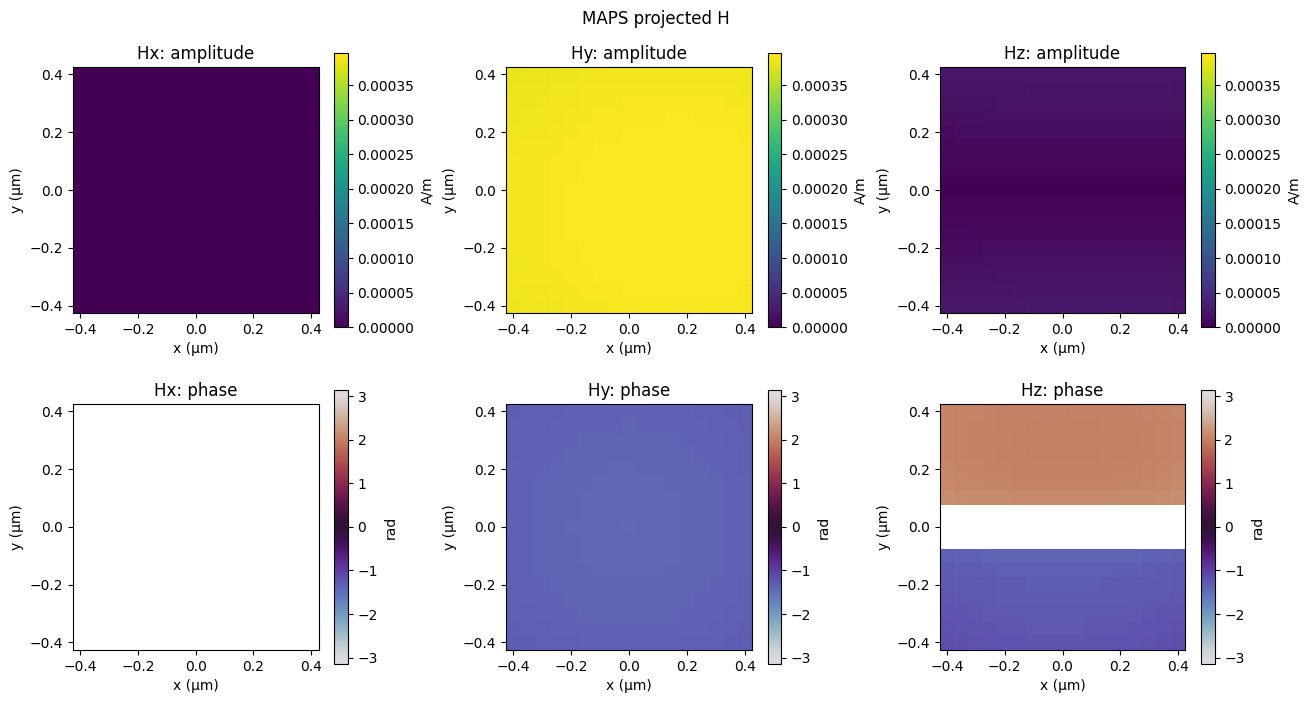

label,relative_complex_l2,relative_amplitude_l2,phase_rms_rad,strong_relative_l2,weak_absolute_over_peak,strong_count,weak_count
E: Tidy3D vs MAPS,1.5314e-06,1.5042e-07,1.5183e-06,1.5314e-06,N/A,289,0
H: Tidy3D vs MAPS,1.5275e-06,9.5447e-08,1.5292e-06,1.5275e-06,N/A,289,0


In [ ]:
try:
    import xarray as xr
    import tidy3d as td
except ImportError as exc:
    print(
        f"Tidy3D comparison unavailable ({type(exc).__name__}: {exc}). Install Tidy3D and xarray for the comparison."
    )
    TIDY_AVAILABLE = False
else:
    TIDY_AVAILABLE = True

if TIDY_AVAILABLE:
    axis_um = np.linspace(-0.4, 0.4, 17)
    axis_m = torch.as_tensor(
        axis_um * 1e-6,
        device=DEVICE,
        dtype=torch.float32 if DEVICE.type == "cuda" else torch.float64,
    )
    yy_t, xx_t = torch.meshgrid(axis_m, axis_m, indexing="ij")
    target = torch.stack(
        (xx_t, yy_t, torch.full_like(xx_t, 4 * wavelength)), dim=-1
    ).reshape(-1, 3)
    ctype = torch.complex64 if DEVICE.type == "cuda" else torch.complex128
    surf = surface_copy(surface_ref, device=DEVICE, dtype=ctype)
    me, mh = project_nearfield(surf, target)
    me = me[0].detach().cpu().numpy().reshape(17, 17, 3)
    mh = mh[0].detach().cpu().numpy().reshape(17, 17, 3)

    # Tidy3D monitor coordinates are in µm; inputs stay exactly the same samples.
    def da(v):
        return xr.DataArray(
            np.asarray(v).T[:, :, None, None],
            coords={
                "x": u.numpy() * 1e6,
                "y": u.numpy() * 1e6,
                "z": [0.0],
                "f": [freq],
            },
            dims=("x", "y", "z", "f"),
        )

    mon = td.FieldMonitor(
        center=(0, 0, 0),
        size=(2, 2, 0),
        freqs=[freq],
        name="shared",
        fields=["Ex", "Ey", "Ez", "Hx", "Hy", "Hz"],
        colocate=True,
    )
    fd = td.FieldData(
        monitor=mon,
        Ex=da(e[0, ..., 0].numpy()),
        Ey=da(e[0, ..., 1].numpy()),
        Ez=da(e[0, ..., 2].numpy()),
        Hx=da(h[0, ..., 0].numpy()),
        Hy=da(h[0, ..., 1].numpy()),
        Hz=da(h[0, ..., 2].numpy()),
    )
    projector, pm = td.FieldProjector.from_near_field_data(
        near_field_data=fd,
        name="same_input",
        x=axis_um.tolist(),
        y=axis_um.tolist(),
        proj_axis=2,
        proj_distance=4 * wavelength * 1e6,
        normal_dir="+",
        medium=td.Medium(),
        dimensionality="3D",
        pts_per_wavelength=None,
        origin=(0, 0, 0),
        far_field_approx=False,
    )
    result = projector.project_fields(pm)
    fc = result.fields_cartesian
    te = np.stack([fc[k].values[:, :, 0, 0].T for k in ("Ex", "Ey", "Ez")], axis=-1)
    th = np.stack([fc[k].values[:, :, 0, 0].T for k in ("Hx", "Hy", "Hz")], axis=-1)
    _ = field_comparison(
        te,
        me,
        axis_um,
        axis_um,
        names=("Tidy3D", "MAPS"),
        quantity="E",
        units="V/m",
        component=0,
    )
    _ = field_components(
        me, axis_um, axis_um, title="MAPS projected E", quantity="E", units="V/m"
    )
    _ = field_components(
        mh, axis_um, axis_um, title="MAPS projected H", quantity="H", units="A/m"
    )
    errors = [
        error_summary(te, me, label="E: Tidy3D vs MAPS"),
        error_summary(th, mh, label="H: Tidy3D vs MAPS"),
    ]
    show_errors(errors)
    assert (
        max(v["relative_complex_l2"] for v in errors) < 2e-5
    ), f"Regression gate failed: {errors}"
else:
    # Keep the native projection visualization useful when the optional package is absent.
    target_axis_um = np.linspace(-0.4, 0.4, 17)
    target_axis_m = torch.as_tensor(target_axis_um * 1e-6, dtype=torch.float64)
    yy_t, xx_t = torch.meshgrid(target_axis_m, target_axis_m, indexing="ij")
    target = torch.stack(
        (xx_t, yy_t, torch.full_like(xx_t, 4 * wavelength)), dim=-1
    ).reshape(-1, 3)
    me, mh = project_nearfield(surface_ref, target)
    _ = field_components(
        me[0].detach().numpy().reshape(17, 17, 3),
        target_axis_um,
        target_axis_um,
        title="MAPS projected E (Tidy3D unavailable)",
        quantity="E",
        units="V/m",
    )
    _ = field_components(
        mh[0].detach().numpy().reshape(17, 17, 3),
        target_axis_um,
        target_axis_um,
        title="MAPS projected H (Tidy3D unavailable)",
        quantity="H",
        units="A/m",
    )

## Far-field agreement and measured forward costs

The far-field comparison restores the outgoing radial factor to the Torch coefficients. The timing chart labels CPU/GPU and dtype; Tidy3D host memory is unmeasured.

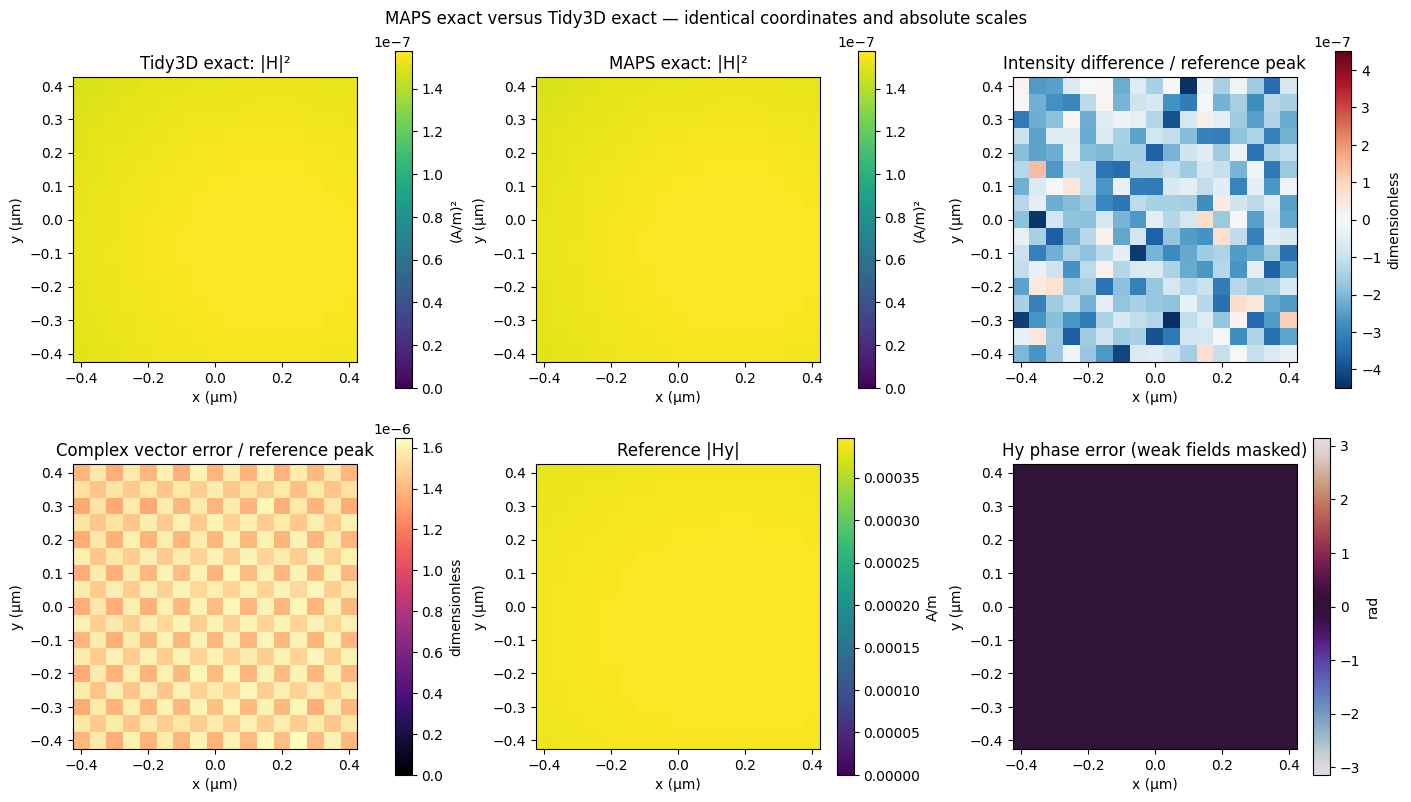

00:04:38 MST WARNING: Monitor data requires 'grid_expanded' to be defined to    
             compute values like flux, Poynting and dot product with other data.

             WARNING: Monitor data requires 'grid_expanded' to be defined to    
             compute values like flux, Poynting and dot product with other data.

             WARNING: Monitor data requires 'grid_expanded' to be defined to    
             compute values like flux, Poynting and dot product with other data.

label,relative_complex_l2,relative_amplitude_l2,phase_rms_rad,strong_relative_l2,weak_absolute_over_peak,strong_count,weak_count
far E: Tidy3D vs Torch c128,1.6362e-11,4.4439e-14,1.6362e-11,1.6362e-11,N/A,289,0
far H: Tidy3D vs Torch c128,1.6362e-11,5.399e-14,1.6362e-11,1.6362e-11,N/A,289,0


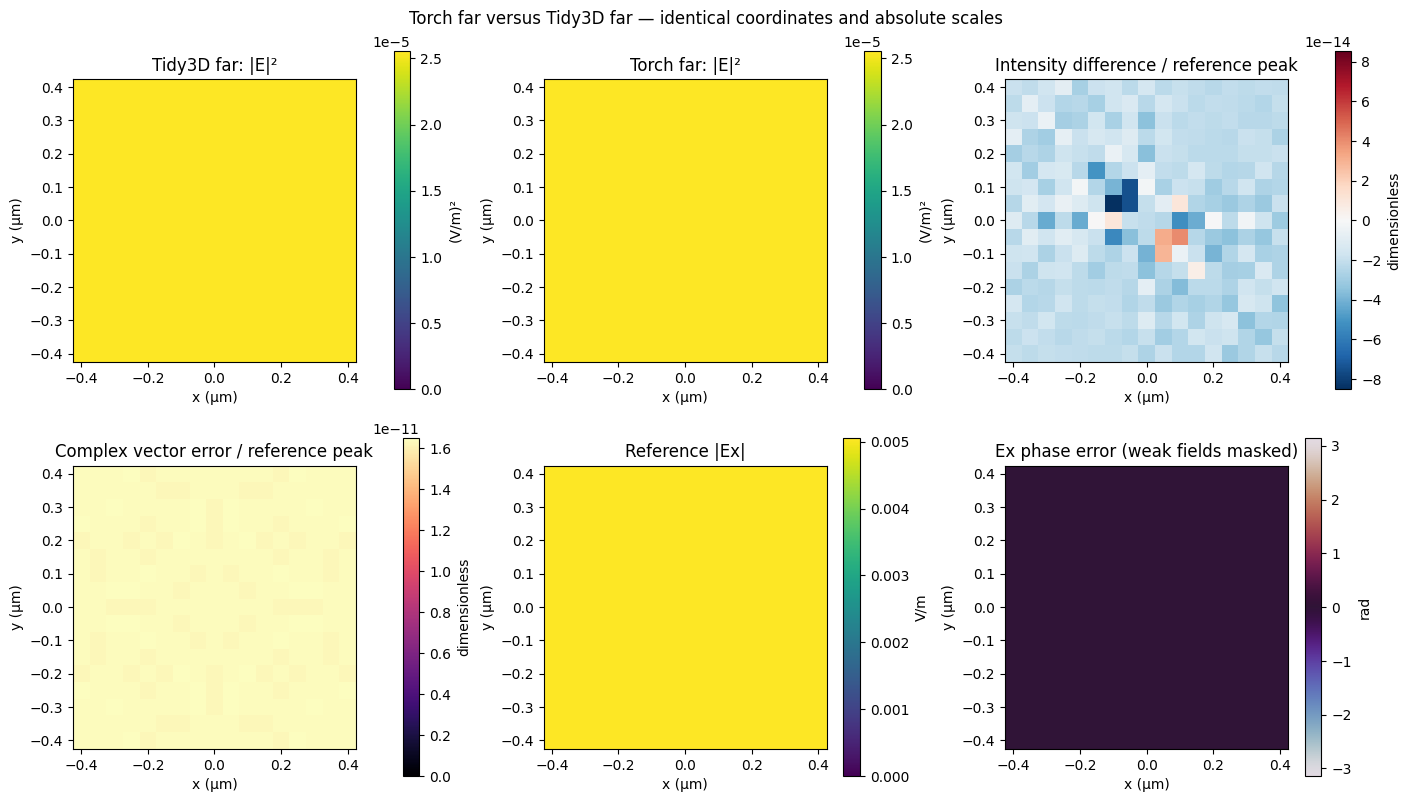

Tidy3D exact forward (CPU, complex128 input): 25.899 ms median; Torch timing follows (selected device, explicitly reported dtype).


method,device,dtype,output_shape,first_forward_ms,warm_forward_ms,warm_backward_ms,warm_forward_backward_ms,peak_allocated_mib,peak_increment_mib,first_gradient_forward_ms,first_backward_ms,warmups,repeats
Tidy3D exact CPU,cpu,complex128,"(1,289,3)",N/A,25.899,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
"Torch exact forward (cuda, torch.complex64)",cuda,torch.complex64,"(1, 289, 3)",26.427,25.773,N/A,N/A,22.821,14.545,N/A,N/A,1,3


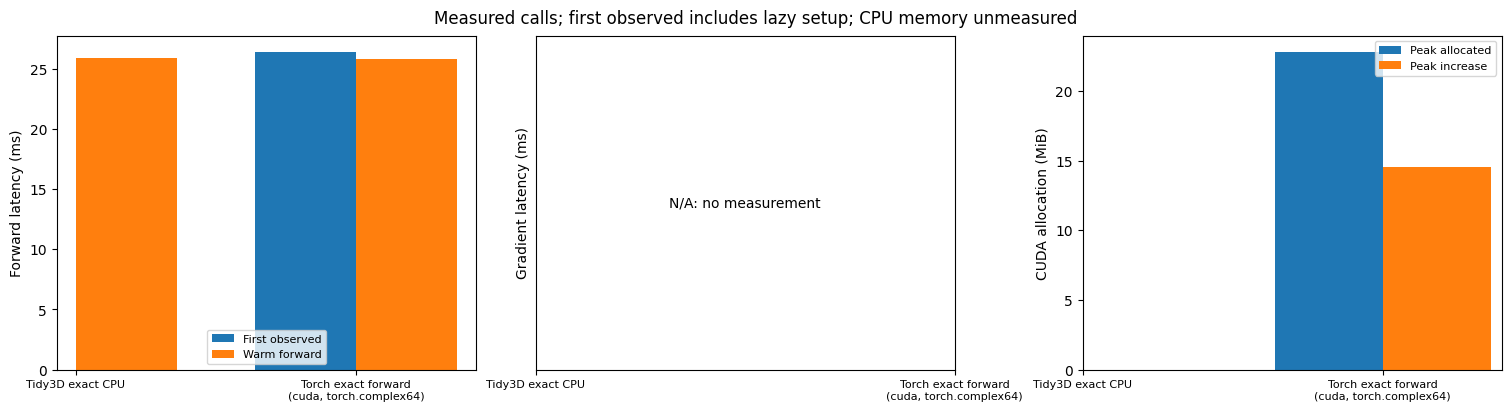

Forward-only timing; backend hardware differs and Tidy3D has no synthetic backward measurement.


In [ ]:
if TIDY_AVAILABLE:
    _ = field_comparison(
        th,
        mh,
        axis_um,
        axis_um,
        names=("Tidy3D exact", "MAPS exact"),
        quantity="H",
        units="A/m",
        component=1,
    )

# Append as a code cell after the existing exact Tidy3D/MAPS comparison cell.
# Tidy3D variables (fd, projector, pm, axis_um, freq, wavelength, target,
# surface_ref, DEVICE, e, h) are defined only when TIDY_AVAILABLE is True.
if TIDY_AVAILABLE:
    from core.nearfield import C_0, project_farfield
    from notebook_utils import (
        benchmark_methods,
        error_summary,
        show_errors,
        show_benchmarks,
        surface_copy,
    )
    import time

    # Compare Tidy3D's far-field approximation and Torch's radiation-zone
    # projection on the same target directions and physical observation radius.
    far_distance_um = 120.0 * wavelength * 1e6
    far_projector, far_monitor = td.FieldProjector.from_near_field_data(
        near_field_data=fd,
        name="same_input_far",
        x=axis_um.tolist(),
        y=axis_um.tolist(),
        proj_axis=2,
        proj_distance=far_distance_um,
        normal_dir="+",
        medium=td.Medium(),
        dimensionality="3D",
        pts_per_wavelength=None,
        origin=(0, 0, 0),
        far_field_approx=True,
    )
    far_result = far_projector.project_fields(far_monitor, verbose=False)
    far_cart = far_result.fields_cartesian
    tidy_far_e = np.stack(
        [far_cart[k].values[:, :, 0, 0].T for k in ("Ex", "Ey", "Ez")], axis=-1
    )
    tidy_far_h = np.stack(
        [far_cart[k].values[:, :, 0, 0].T for k in ("Hx", "Hy", "Hz")], axis=-1
    )
    yy_um, xx_um = np.meshgrid(axis_um, axis_um, indexing="ij")
    points_m = (
        np.stack((xx_um, yy_um, np.full_like(xx_um, far_distance_um)), axis=-1).reshape(
            -1, 3
        )
        * 1e-6
    )
    radii_m = np.linalg.norm(points_m, axis=-1)
    directions = points_m / radii_m[:, None]
    far_surface = surface_copy(surface_ref, device=DEVICE, dtype=torch.complex128)
    directions_t = torch.as_tensor(
        directions, device=DEVICE, dtype=far_surface.positions_m.dtype
    )
    torch_far_e, torch_far_h = project_farfield(
        far_surface, directions_t, source_chunk_size=512, observation_chunk_size=256
    )
    radius_t = torch.as_tensor(
        radii_m, device=DEVICE, dtype=far_surface.positions_m.dtype
    )
    radial_factor = torch.exp(1j * (2 * torch.pi * freq / C_0) * radius_t) / radius_t
    torch_far_e = (
        (torch_far_e[0] * radial_factor[:, None])
        .detach()
        .cpu()
        .numpy()
        .reshape(17, 17, 3)
    )
    torch_far_h = (
        (torch_far_h[0] * radial_factor[:, None])
        .detach()
        .cpu()
        .numpy()
        .reshape(17, 17, 3)
    )
    far_errors = [
        error_summary(tidy_far_e, torch_far_e, label="far E: Tidy3D vs Torch c128"),
        error_summary(tidy_far_h, torch_far_h, label="far H: Tidy3D vs Torch c128"),
    ]
    show_errors(far_errors)
    assert max(row["relative_complex_l2"] for row in far_errors) < 2e-5, far_errors
    _ = field_comparison(
        tidy_far_e,
        torch_far_e,
        axis_um,
        axis_um,
        names=("Tidy3D far", "Torch far"),
        quantity="E",
        units="V/m",
        component=0,
    )

    # Forward-only timing on labeled hardware. Tidy3D is timed on CPU. Torch
    # uses the selected device and reports dtype; no fake Tidy3D backward.
    def timed_tidy_cpu(fn, warmups=1, repeats=3):
        for _ in range(warmups):
            fn()
        samples = []
        for _ in range(repeats):
            t0 = time.perf_counter()
            fn()
            samples.append((time.perf_counter() - t0) * 1e3)
        return float(np.median(samples))

    def tidy_exact_forward():
        return projector.project_fields(pm, verbose=False)

    maps_surface = surface_copy(
        surface_ref,
        device=DEVICE,
        dtype=torch.complex64 if DEVICE.type == "cuda" else torch.complex128,
    )
    target_device = target.to(device=DEVICE, dtype=maps_surface.positions_m.dtype)

    def torch_exact_forward():
        return project_nearfield(maps_surface, target_device)

    tidy_ms = timed_tidy_cpu(tidy_exact_forward)
    torch_records = benchmark_methods(
        {
            "Torch exact forward ("
            + str(DEVICE)
            + ", "
            + str(maps_surface.electric_fields.dtype)
            + ")": torch_exact_forward
        },
        device=DEVICE,
        warmups=1,
        repeats=3,
    )
    print(
        f"Tidy3D exact forward (CPU, complex128 input): {tidy_ms:.3f} ms median; Torch timing follows (selected device, explicitly reported dtype)."
    )
    tidy_record = dict(
        method="Tidy3D exact CPU",
        device="cpu",
        dtype="complex128",
        output_shape="(1,289,3)",
        first_forward_ms=None,
        warm_forward_ms=tidy_ms,
        warm_backward_ms=None,
        warm_forward_backward_ms=None,
        peak_allocated_mib=None,
        peak_increment_mib=None,
    )
    show_benchmarks([tidy_record, *torch_records])
    print(
        "Forward-only timing; backend hardware differs and Tidy3D has no synthetic backward measurement."
    )

Phase comparisons are masked where the reference field is weak or null. The common physical color scale and global complex error avoid hiding magnitude disagreement through separate normalization. E-field intensity remains an |E|² proxy rather than measured flux.